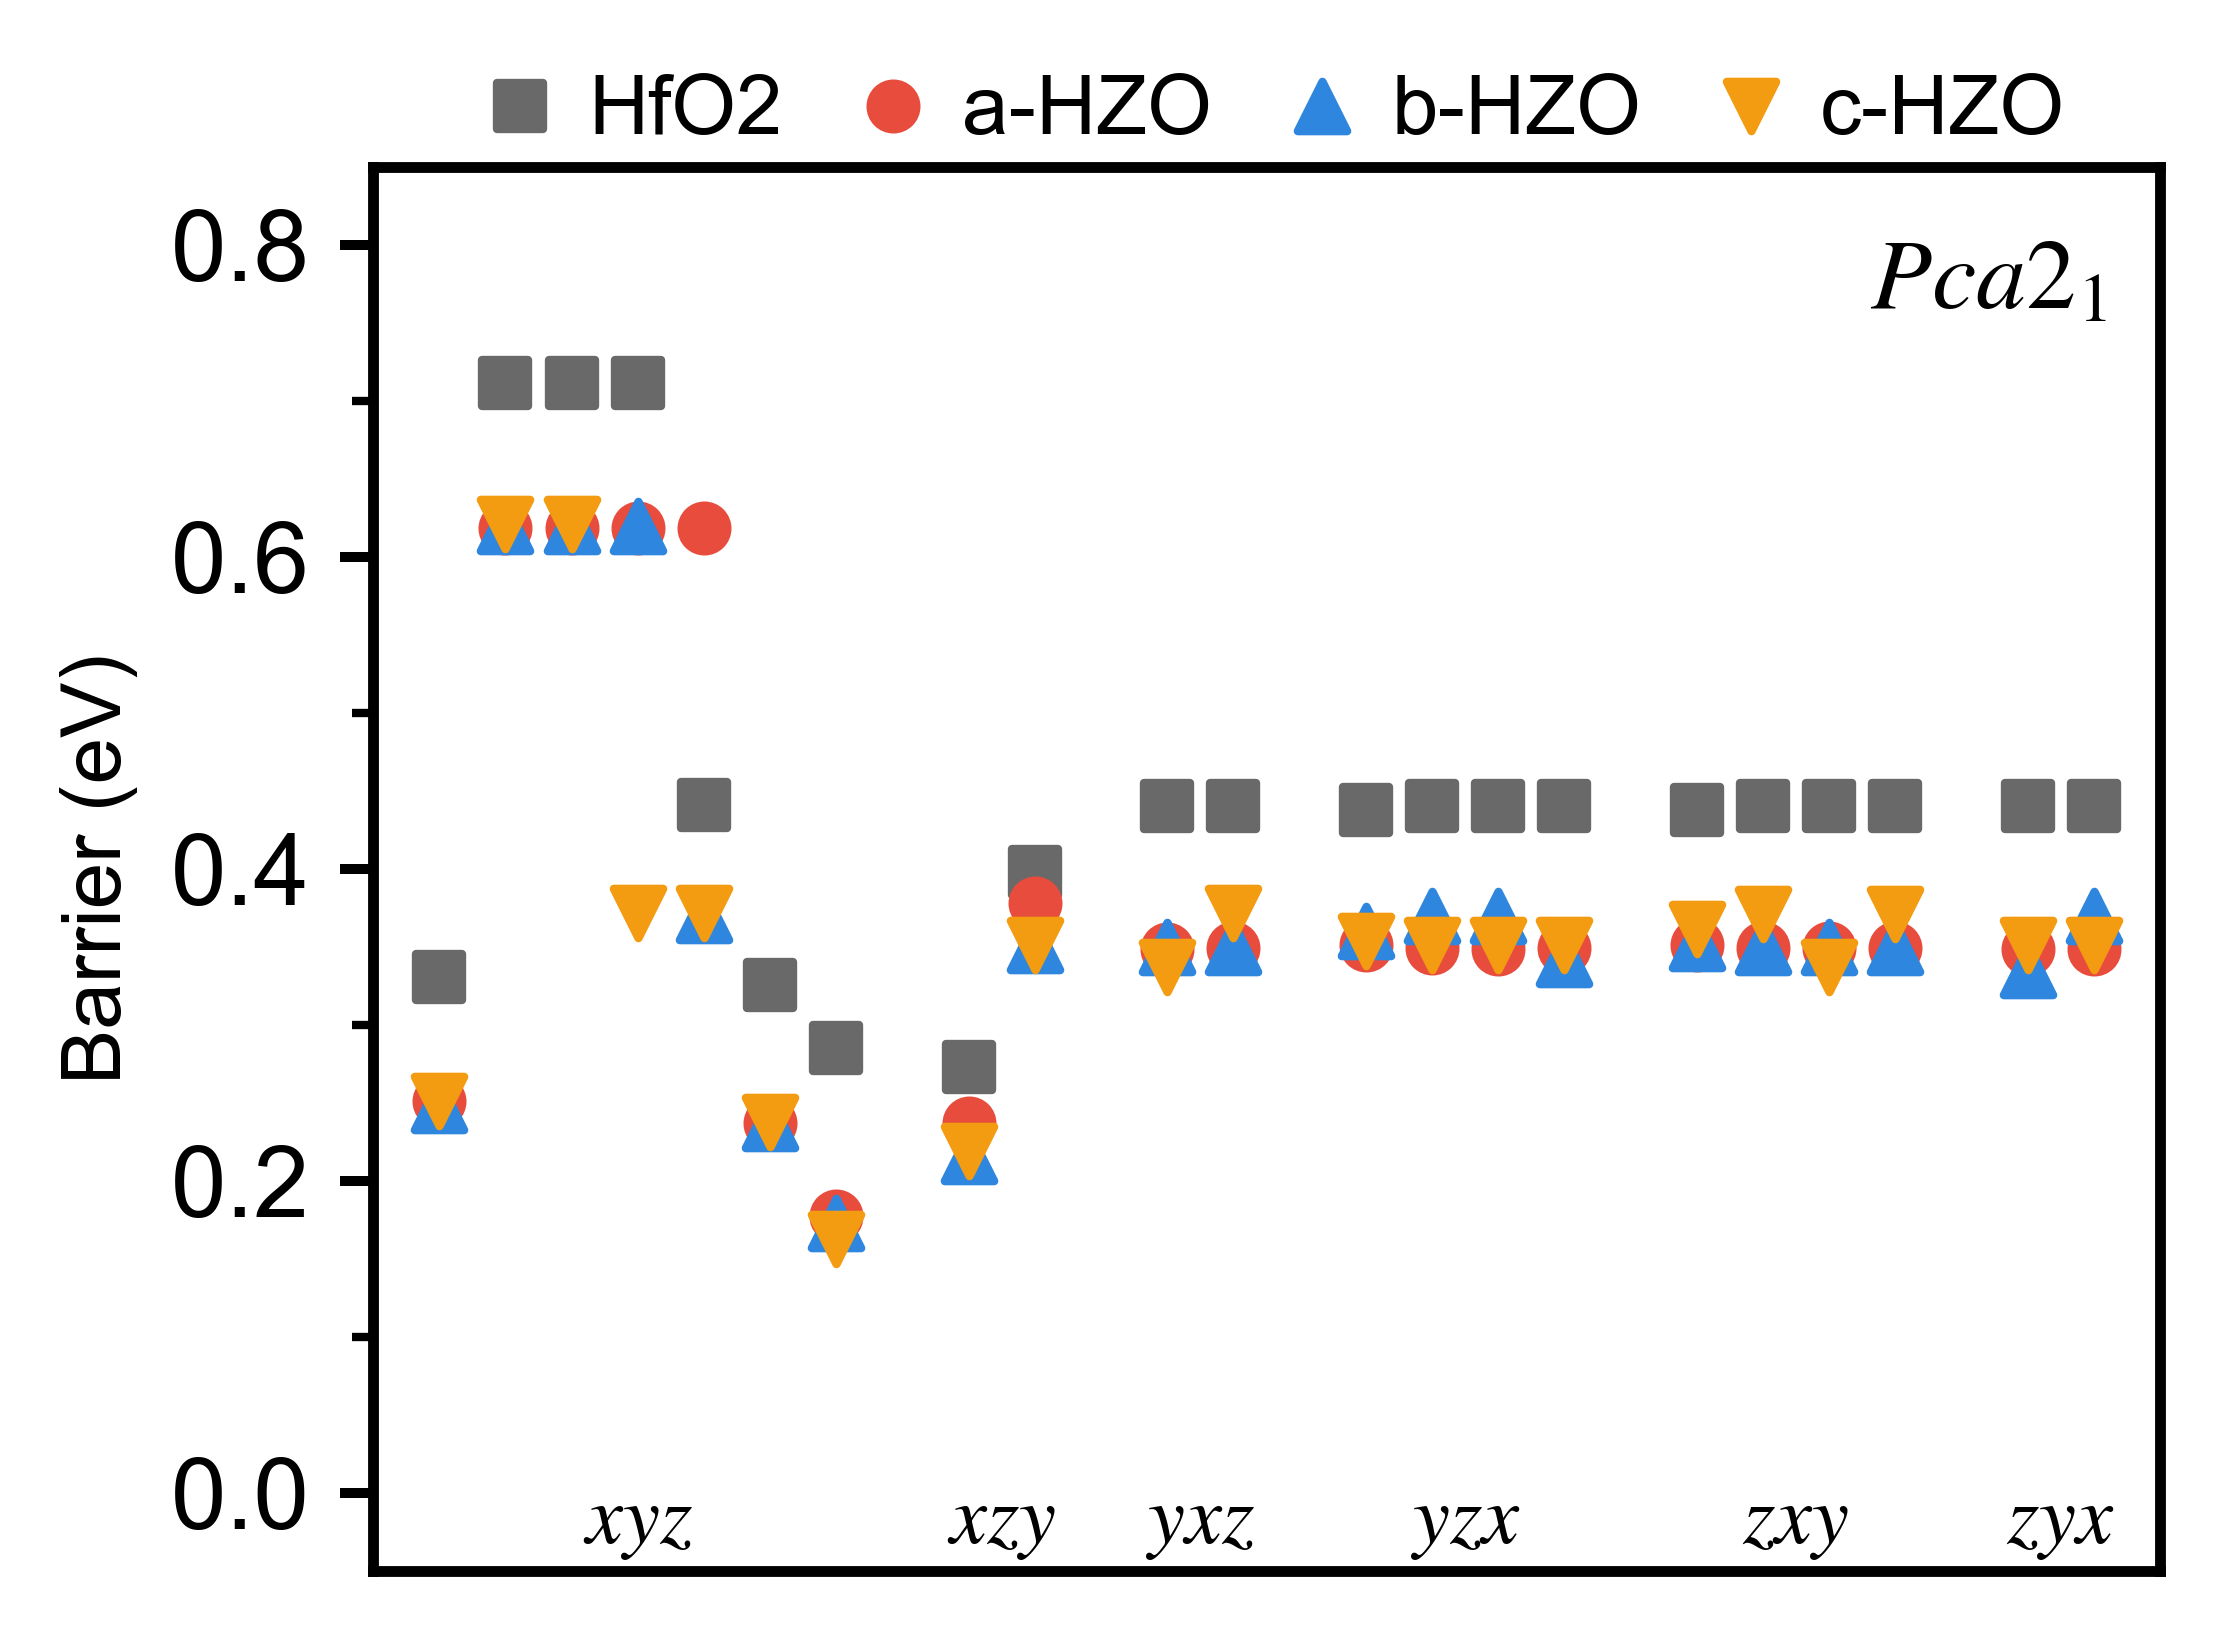

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import AutoMinorLocator

# ========= set the style =========
rcParams.update({
    # ==== font ====
    "font.family": "Arial", # times new roman, arial, stix
    "mathtext.fontset": "stix", # ['dejavusans', 'dejavuserif', 'cm', 'stix', 'stixsans', 'custom']
    "axes.unicode_minus": False,

    # === figure resolution ===
    "figure.dpi": 600,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",

    # ==== axes ====
    "axes.linewidth": 1.3,

    # ==== lines and markers ====
    "lines.linewidth": 1.4,
    "lines.markersize": 5.0,
    "lines.markeredgewidth": 1.2,

    # ==== ticks ====
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 1.0,
    "ytick.minor.width": 1.0,

    "xtick.major.size": 4,
    "xtick.minor.size": 2.5,
    "ytick.major.size": 4,
    "ytick.minor.size": 2.5,

    "xtick.labelsize": 12,
    "ytick.labelsize": 12,

    # ==== legend ====
    "legend.frameon": False,
#     "legend.fontsize": 9,
    
    # ==== export ====
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def plot_pca21_barrier(csv_path):


    # ========= 读取数据 =========
    df = pd.read_csv(csv_path)
    data = df.iloc[2:].reset_index(drop=True)

    # 第一列：用于分组
    raw_label = data.iloc[:, 0].astype(str)

    # 第二列：x 轴数值
    x = data.iloc[:, 1].astype(float).values

    # 分组标签（- 前面的部分）
    group_labels = raw_label.str.split("-").str[0]

    # 能量数据
    hfo2 = data.iloc[:, 2].astype(float)
    a_hzo = data.iloc[:, 3].astype(float)
    b_hzo = data.iloc[:, 4].astype(float)
    c_hzo = data.iloc[:, 5].astype(float)

    # ========= 作图 =========
    fig, ax = plt.subplots(figsize=(3.8, 2.8))

    ax.scatter(x, hfo2, marker="s", s=30, color="dimgray", label="HfO2")
    ax.scatter(x, a_hzo, marker="o", s=30, color="#e74c3c", label="a-HZO")
    ax.scatter(x, b_hzo, marker="^", s=35, color="#2e86de", label="b-HZO")
    ax.scatter(x, c_hzo, marker="v", s=35, color="#f39c12", label="c-HZO")

    # ========= 分组处理 =========
    unique_groups = group_labels.unique()

    group_centers = []
    boundary_ticks = []

    for g in unique_groups:
        idx = np.where(group_labels == g)[0]
        x_group = x[idx]

        center = x_group.mean()
        group_centers.append(center)

        # 计算分组之间的边界位置
        if len(boundary_ticks) == 0:
            pass
        else:
            prev_last = x[np.where(group_labels == unique_groups[list(unique_groups).index(g)-1])[0][-1]]
            boundary = (prev_last + x_group[0]) / 2
            boundary_ticks.append(boundary)

        # 第一组不加边界
        if len(boundary_ticks) == 0 and len(group_centers) > 1:
            prev_last = x[np.where(group_labels == unique_groups[0])[0][-1]]
            boundary = (prev_last + x_group[0]) / 2
            boundary_ticks.append(boundary)

    # 重新计算 boundary（更清晰写法）
    boundary_ticks = []
    for i in range(len(unique_groups) - 1):
        g1 = unique_groups[i]
        g2 = unique_groups[i + 1]

        last_x_g1 = x[np.where(group_labels == g1)[0][-1]]
        first_x_g2 = x[np.where(group_labels == g2)[0][0]]

        boundary_ticks.append((last_x_g1 + first_x_g2) / 2)

    # ========= 设置 x 轴 ticks =========
    all_xticks = list(x) + boundary_ticks
    all_xticks = sorted(all_xticks)

    ax.set_xticks(all_xticks)

    # 原始数据点显示刻度，边界刻度不显示label
    xtick_labels = []
    for tick in all_xticks:
        if tick in x:
            xtick_labels.append(str(int(tick)))
        else:
            xtick_labels.append("")

    ax.set_xticklabels(xtick_labels)

    # ========= 在上方添加分组标签 =========
    for center, label in zip(group_centers, unique_groups):
        ax.text(center,
                0.02,
                r"$" + label + "$",
                transform=ax.get_xaxis_transform(),
                ha="center", fontweight="normal")

    # ========= 其他格式 =========
    ax.set_ylabel("Barrier (eV)")
    ax.set_ylim(-0.05, 0.85)
    ax.set_xlim(min(x) - 1, max(x) + 1)
    ax.set_xticks([])
    ax.tick_params(axis="y", which="both", left=True, right=False)
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.legend(loc="upper center",
              bbox_to_anchor=(0.5, 1.10),
              ncol=4,
              fontsize=10,
              handlelength=1.25,
              handleheight=1,
              borderaxespad=0.4,
              columnspacing=0.7,
              labelspacing=0.1,
              handletextpad=0.2,
              borderpad=0.1)

    ax.text(0.97, 0.95,
            r"$Pca2_1$",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=12,
            fontstyle="italic", fontweight="normal")

    plt.tight_layout()
    plt.show()


# 调用
plot_pca21_barrier("fig_2a_pca2_1_energy_barrier/fig_2a.csv")